# Import Libraries

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Load Dataset

In [5]:
df = pd.read_csv('/content/Cars_Analysis/data.csv')

# Initial Data Exploration

In [6]:
df.head(10)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500
5,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,31200
6,BMW,1 Series,2012,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,26,17,3916,44100
7,BMW,1 Series,2012,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,39300
8,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,36900
9,BMW,1 Series,2013,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,27,18,3916,37200


In [7]:
df.tail(10)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
11904,BMW,Z8,2002,premium unleaded (required),394.0,8.0,MANUAL,rear wheel drive,2.0,"Exotic,Luxury,High-Performance",Compact,Convertible,19,12,3916,130000
11905,BMW,Z8,2003,premium unleaded (required),394.0,8.0,MANUAL,rear wheel drive,2.0,"Exotic,Luxury,High-Performance",Compact,Convertible,19,12,3916,131500
11906,Acura,ZDX,2011,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,46020
11907,Acura,ZDX,2011,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,56570
11908,Acura,ZDX,2011,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50520
11909,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,46120
11910,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,56670
11911,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50620
11912,Acura,ZDX,2013,premium unleaded (recommended),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50920
11913,Lincoln,Zephyr,2006,regular unleaded,221.0,6.0,AUTOMATIC,front wheel drive,4.0,Luxury,Midsize,Sedan,26,17,61,28995


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

In [9]:
df.shape

(11914, 16)

In [10]:
df.isnull().sum()

,0
Make,0
Model,0
Year,0
Engine Fuel Type,3
Engine HP,69
Engine Cylinders,30
Transmission Type,0
Driven_Wheels,0
Number of Doors,6
Market Category,3742


In [11]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='object')

# Handling Missing Value

In [12]:
df['Market Category'] = df['Market Category'].fillna('Not Specified')

In [13]:
df['Market Category'].isnull().sum()

np.int64(0)

In [14]:
df['Engine HP'] = df.groupby('Model')['Engine HP'].transform(lambda x: x.fillna(x.median()))
df['Engine Cylinders'] = df.groupby('Model')['Engine Cylinders'].transform(lambda x: x.fillna(x.median()))

In [15]:
df['Engine HP'] = df['Engine HP'].fillna(df['Engine HP'].median())
df['Engine Cylinders'] = df['Engine Cylinders'].fillna(df['Engine Cylinders'].median())

In [16]:
df['Number of Doors'] = df['Number of Doors'].fillna(df['Number of Doors'].median())

In [17]:
df.dropna(subset=['Engine Fuel Type'],inplace=True)

 # Data Type Conversion

In [18]:
float_columns = [ 'Engine HP','Engine Cylinders','Number of Doors']
for col in float_columns:
    df[col] = df[col].astype('int')

# Remove Duplicates

In [19]:
df.duplicated().sum()

np.int64(715)

In [20]:
df = df.drop_duplicates()

In [21]:
df.duplicated().sum()

np.int64(0)

# Feature Engineering

In [22]:
df['Car_Age'] = 2026 - df['Year']

In [23]:
df[['Year', 'Car_Age']].head()

,Year,Car_Age
0,2011,15
1,2011,15
2,2011,15
3,2011,15
4,2011,15


# Standardize Column Names

In [24]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

# Final Verification & Exploratory Analysis

In [25]:
df.isnull().sum()

,0
make,0
model,0
year,0
engine_fuel_type,0
engine_hp,0
engine_cylinders,0
transmission_type,0
driven_wheels,0
number_of_doors,0
market_category,0


In [26]:
df[df["msrp"] > 300000][["make", "model", "msrp"]]

,make,model,msrp
611,Maybach,57,366000
612,Maybach,57,455500
613,Maybach,57,405500
614,Maybach,57,372500
615,Maybach,57,412000
...,...,...,...
11213,Aston Martin,Vanquish,320695
11362,Bugatti,Veyron 16.4,2065902
11363,Bugatti,Veyron 16.4,1500000
11364,Bugatti,Veyron 16.4,1705769


# Save Cleaned Dataset

In [27]:
df.to_csv('data_cleaned.csv', index=False)

# EDA

## Outlier
### MSRP Distribution Before and After Log Transformation

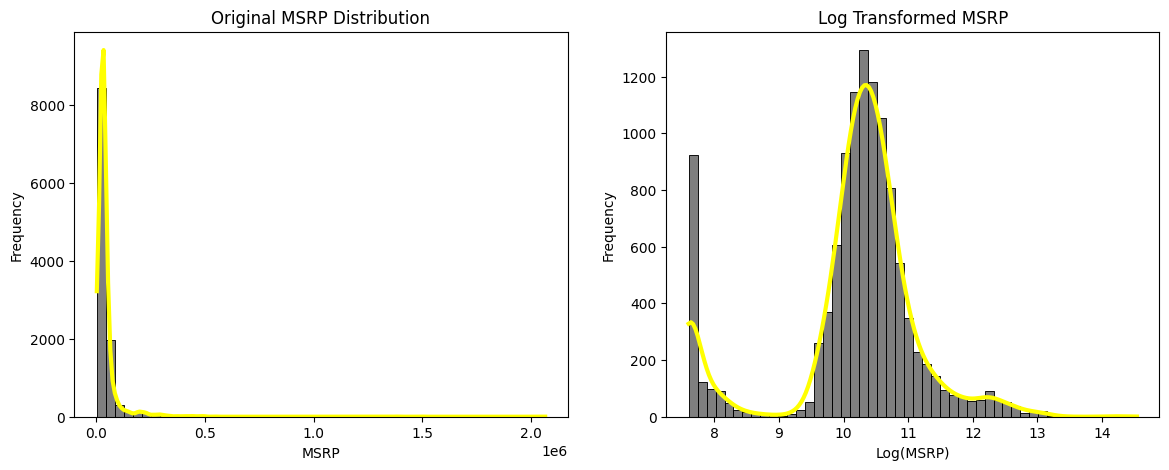

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["msrp"], bins=50, kde=True, color="black", ax=axes[0])
axes[0].set_title('Original MSRP Distribution')
axes[0].set_xlabel('MSRP')
axes[0].set_ylabel('Frequency')
axes[0].lines[0].set_color("yellow")
axes[0].lines[0].set_linewidth(3)


log_msrp = np.log(df['msrp'])
sns.histplot(log_msrp, bins=50, kde=True, color="black", ax=axes[1])
axes[1].set_title('Log Transformed MSRP')
axes[1].set_xlabel('Log(MSRP)')
axes[1].set_ylabel('Frequency')
axes[1].lines[0].set_color("yellow")
axes[1].lines[0].set_linewidth(3)
plt.show()

## Correlation Matrix Heatmap

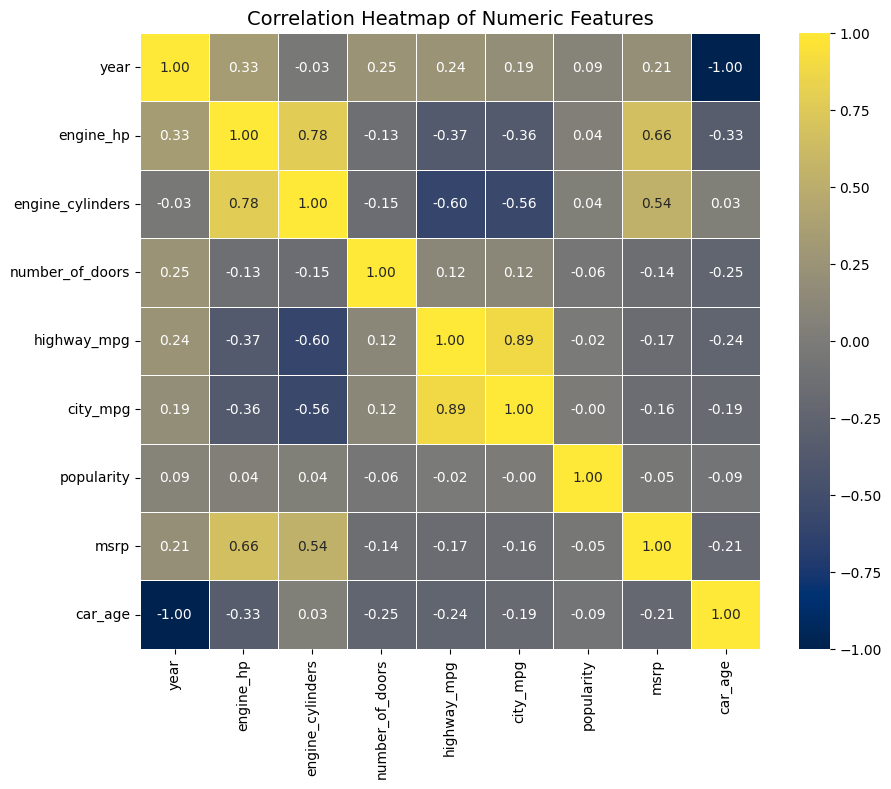

In [77]:
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='cividis',linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features', fontsize=14)
plt.show()


## Encoding Categorical Features

In [79]:
num_cols = ['engine_hp', 'engine_cylinders', 'number_of_doors', 'highway_mpg', 'city_mpg', 'popularity', 'car_age']
cat_cols = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels', 'vehicle_size', 'vehicle_style']

encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_cat = encoder.fit_transform(df[cat_cols])
X_cat_df = pd.DataFrame(X_cat, columns=encoder.get_feature_names_out(cat_cols))


X = pd.concat([df[num_cols].reset_index(drop=True), X_cat_df.reset_index(drop=True)], axis=1)

## Models

## Linear Regression (Regression Model)

### Split Train/Test

In [86]:
y_reg = np.log(df['msrp'])

X_train_r, X_test_r, y_train_r_log, y_test_r_log = train_test_split(X, y_reg, test_size=0.2, random_state=42)

### Linear Regression Model Training

In [87]:
reg_model = LinearRegression()
reg_model.fit(X_train_r, y_train_r_log)

LinearRegression()

### Model Prediction

In [81]:
y_pred_log = reg_model.predict(X_test_r)
y_pred_orig = np.expm1(y_pred_log)
y_test_orig = np.expm1(y_test_r_log)

### Model Evaluation

In [82]:
rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
mae = mean_absolute_error(y_test_orig, y_pred_orig)
r2 = r2_score(y_test_r_log, y_pred_log)

print(f"R² Score (Log Scale) : {r2:.4f}")
print(f"MAE (Original Currency): ${mae:,.2f}")
print(f"RMSE (Original Currency): ${rmse:,.2f}")

R² Score (Log Scale) : 0.8538
MAE (Original Currency): $10,577.22
RMSE (Original Currency): $26,456.81


## Random Forest (Classification Model)

### Split Train/Test

In [83]:
y_class, bin_edges = pd.qcut(df['msrp'], q=3, labels=['Budget', 'Mid-Range', 'Luxury'], retbins=True)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)

### Standerd Scaling

In [84]:
scaler = StandardScaler()
X_train_c_scaled = scaler.fit_transform(X_train_c)
X_test_c_scaled = scaler.transform(X_test_c)

### Random Forest Model Training

In [85]:
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train_c, y_train_c)

RandomForestClassifier(random_state=42)

### Model Prediction

In [88]:
y_pred_class = clf_model.predict(X_test_c)

### Model Evaluation

In [89]:
rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
mae = mean_absolute_error(y_test_orig, y_pred_orig)
r2 = r2_score(y_test_r_log, y_pred_log)

print(f"R² Score (Log Scale) : {r2:.4f}")
print(f"MAE (Original Currency): ${mae:,.2f}")
print(f"RMSE (Original Currency): ${rmse:,.2f}")

R² Score (Log Scale) : 0.8538
MAE (Original Currency): $10,577.22
RMSE (Original Currency): $26,456.81


## Comparison between Regression vs Classification

### Converting Predicted Prices into Price Categories

In [90]:
reg_as_class = pd.cut(y_pred_orig,bins=bin_edges,labels=['Budget', 'Mid-Range', 'Luxury'],include_lowest=True,)


### Classification Performance Comparison

In [91]:
clf_acc = accuracy_score(y_test_c.astype(str), y_pred_class.astype(str))
converted_acc = accuracy_score(y_test_c.astype(str), reg_as_class.astype(str))

In [92]:
comparison = pd.DataFrame({
    'Approach': [
        'Direct Classification',
        'Regression (Converted to Tiers)',
    ],
    'Accuracy': [clf_acc, converted_acc],
})

print(f"1. Direct Classification Model Accuracy : {clf_acc * 100:.2f}%")
print(f"2. Regression Model Accuracy (Converted): {converted_acc * 100:.2f}%\n")

1. Direct Classification Model Accuracy : 88.08%
2. Regression Model Accuracy (Converted): 72.01%



### Conclusion

In [95]:
if clf_acc > converted_acc:
  print(
      'Conclusion: Direct Classification was better at predicting the Price Tier.'
  )
else:
  print(
      'Conclusion: Regression predicts precise price so well that its converted Tiers are highly accurate.'
  )

Conclusion: Direct Classification was better at predicting the Price Tier.


### Classification vs Regression Accuracy Comparison

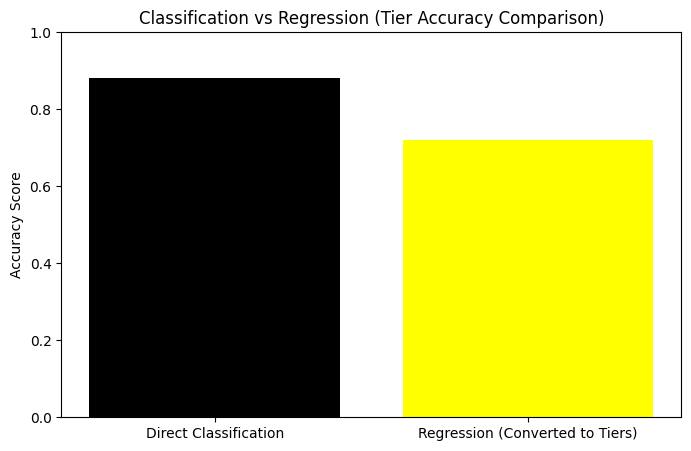

In [97]:
plt.figure(figsize=(8, 5))
plt.bar(comparison['Approach'],comparison['Accuracy'],color=['black', 'yellow'],)
plt.title('Classification vs Regression (Tier Accuracy Comparison)')
plt.ylabel('Accuracy Score')
plt.ylim(0, 1)
plt.show()